In [1]:
# Setup: config + imports
import glob
import os
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import AutoMinorLocator
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Config
CROP_OUT_DIR = "../Data/AIRS-cropped"
CO2_VAR      = "co2_vmr_uppertrop"    # m3/m3 (mol/mol)
CO2_SCALE    = 1e6                    # mol/mol -> ppm
CO_VAR       = "co_mmr_midtrop"
MW_RATIO     = 28.01 / 44.01          # CO / CO2 molar-mass conversion (as in detrend.ipynb)
OUT_DIR      = "../Figures"
os.makedirs(OUT_DIR, exist_ok=True)

# Balanced window: 23 whole years
START_TS = pd.Timestamp("2003-01-01")
END_TS   = pd.Timestamp("2025-12-01")

## Interpolation to fill gaps in the data (2 months)

In [2]:
# Build gap-free monthly (time, lat, lon) cubes over the window. No detrending.
crop_files = sorted(glob.glob(os.path.join(CROP_OUT_DIR, "*.nc")))
print(f"Found {len(crop_files)} cropped files")

months = pd.date_range(START_TS, END_TS, freq="MS")


def load_cube(varname, scale=1.0):
    """Monthly maps (mean over orbit passes), missing months filled by linear
    interpolation in time per pixel."""
    obs_maps = {}
    lons = lats = None
    for f in crop_files:
        stem = os.path.splitext(os.path.basename(f))[0]
        date = pd.Timestamp(f"{stem[:4]}-{stem[4:]}-01")
        if not (START_TS <= date <= END_TS):
            continue
        ds_g = xr.open_dataset(f, decode_timedelta=False)
        if lons is None:
            lons = ds_g["lon"].values
            lats = ds_g["lat"].values
        obs_maps[date] = ds_g[varname].mean(dim="orbit_pass", skipna=True).values * scale
        ds_g.close()

    raw = np.full((len(months), len(lats), len(lons)), np.nan)
    has_obs = np.zeros(len(months), dtype=bool)
    for i, d in enumerate(months):
        if d in obs_maps:
            raw[i] = obs_maps[d]
            has_obs[i] = True

    cube = xr.DataArray(
        raw, dims=("time", "lat", "lon"),
        coords={"time": months, "lat": lats, "lon": lons},
    )
    cube = (cube.interpolate_na(dim="time", method="linear")
                .bfill("time").ffill("time"))
    return cube, raw, has_obs


co2_maps, co2_raw, has_obs = load_cube(CO2_VAR, CO2_SCALE)
lons, lats = co2_maps["lon"].values, co2_maps["lat"].values
is_interp  = ~has_obs

# Time series = spatial mean of each map.
ts_dates = months
ts_co2   = co2_maps.mean(dim=("lat", "lon"), skipna=True).values

# Diagnostics.
n_lat, n_lon = len(lats), len(lons)
filled_dates = [d.strftime('%Y-%m') for d in months[is_interp]]
print(f"Calendar months    : {len(months)}   ({START_TS:%b %Y} - {END_TS:%b %Y})")
print(f"Observed maps      : {has_obs.sum()}")
print(f"Reconstructed maps : {is_interp.sum()}  -> {filled_dates}")
print(f"Grid per map       : {n_lat} lat x {n_lon} lon = {n_lat * n_lon} pixels")
for i in np.where(is_interp)[0]:
    print(f"   {months[i].strftime('%Y-%m')}: map mean = {ts_co2[i]:.3f} ppm")
print(f"Pixels never observed (left NaN): {int(np.isnan(co2_maps.values).all(axis=0).sum())}")
print(f"CO2 range : {np.nanmin(ts_co2):.3f} - {np.nanmax(ts_co2):.3f}  ppm")

Found 279 cropped files


Calendar months    : 276   (Jan 2003 - Dec 2025)
Observed maps      : 274
Reconstructed maps : 2  -> ['2023-09', '2025-12']
Grid per map       : 36 lat x 61 lon = 2196 pixels
   2023-09: map mean = 415.163 ppm
   2025-12: map mean = 419.893 ppm
Pixels never observed (left NaN): 0
CO2 range : 375.034 - 420.764  ppm


## Mean and SD maps

Stack shape : (276, 36, 61)   (2003-01 - 2025-12)
Mean range  : 395.899 - 400.309  ppm
Std  range  : 12.912 - 13.956  ppm


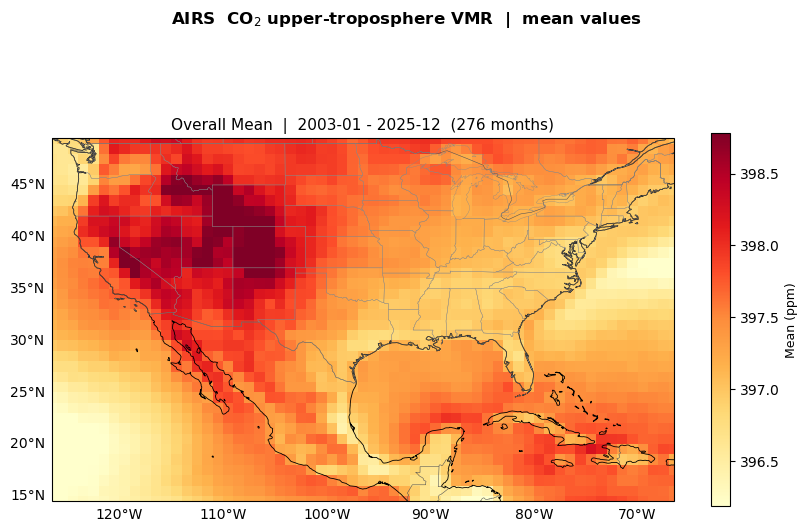

Saved -> ../Figures\co2_vmr_uppertrop_mean_2003_2025.png


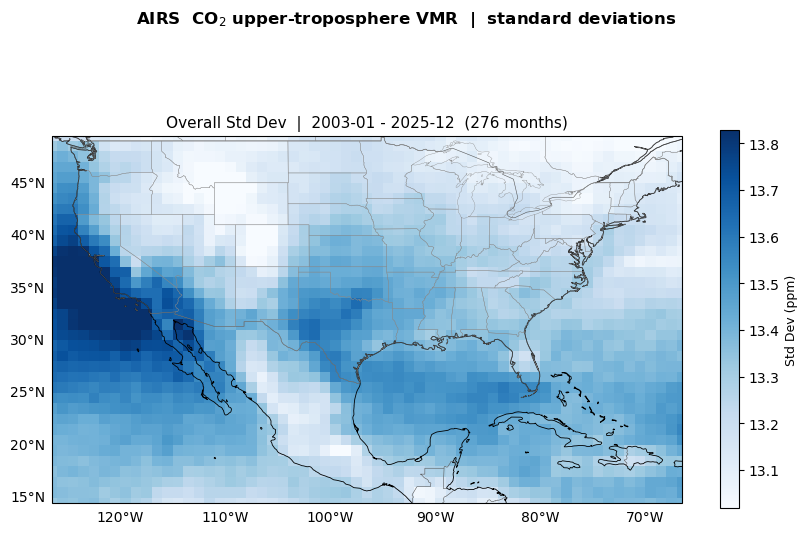

Saved -> ../Figures\co2_vmr_uppertrop_std_2003_2025.png


In [3]:
# Pixel-wise mean & std across all months of the gap-free cube.
stack    = co2_maps.values
co2_mean = np.nanmean(stack, axis=0)
co2_std  = np.nanstd (stack, axis=0, ddof=1)

n_months    = stack.shape[0]
label_first = months[0].strftime("%Y-%m")
label_last  = months[-1].strftime("%Y-%m")

print(f"Stack shape : {stack.shape}   ({label_first} - {label_last})")
print(f"Mean range  : {np.nanmin(co2_mean):.3f} - {np.nanmax(co2_mean):.3f}  ppm")
print(f"Std  range  : {np.nanmin(co2_std ):.3f} - {np.nanmax(co2_std ):.3f}  ppm")

# Map extent from data coords.
lon_min, lon_max = float(lons.min()), float(lons.max())
lat_min, lat_max = float(lats.min()), float(lats.max())


def draw_map(fig, ax, data, cmap, label, title):
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, edgecolor="k")
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, edgecolor="#555")
    ax.add_feature(cfeature.STATES,    linewidth=0.25, edgecolor="#888")

    pcm = ax.pcolormesh(
        lons, lats, data,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        vmin=np.nanpercentile(data, 2), vmax=np.nanpercentile(data, 98),
        shading="nearest",
    )
    gl = ax.gridlines(draw_labels=True, linewidth=0, color="none")
    gl.top_labels = gl.right_labels = False

    cb = fig.colorbar(pcm, ax=ax, orientation="vertical", fraction=0.03, pad=0.06)
    cb.set_label(label, fontsize=9)
    ax.set_title(title, fontsize=11, pad=6)


# Mean map.
fig_mean, ax_mean = plt.subplots(
    figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
draw_map(fig_mean, ax_mean, co2_mean, plt.cm.YlOrRd,
         "Mean (ppm)",
         f"Overall Mean  |  {label_first} - {label_last}  ({n_months} months)")
fig_mean.suptitle(
    "AIRS  CO$_2$ upper-troposphere VMR  |  mean values",
    fontsize=12, fontweight="bold",
)
out_mean = os.path.join(OUT_DIR, "co2_vmr_uppertrop_mean_2003_2025.png")
fig_mean.savefig(out_mean, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_mean)

# Std-dev map.
fig_std, ax_std = plt.subplots(
    figsize=(8, 6), subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True,
)
draw_map(fig_std, ax_std, co2_std, plt.cm.Blues,
         "Std Dev (ppm)",
         f"Overall Std Dev  |  {label_first} - {label_last}  ({n_months} months)")
fig_std.suptitle(
    "AIRS  CO$_2$ upper-troposphere VMR  |  standard deviations",
    fontsize=12, fontweight="bold",
)
out_std = os.path.join(OUT_DIR, "co2_vmr_uppertrop_std_2003_2025.png")
fig_std.savefig(out_std, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_std)

## Timeseries of the spatial mean (not detrended)

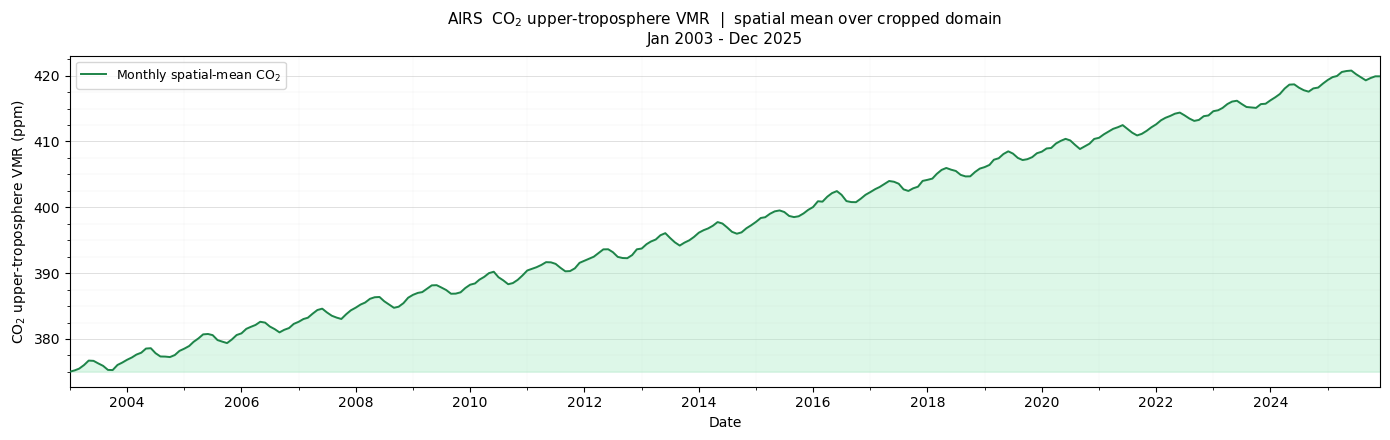

Saved -> ../Figures\timeseries_co2_vmr_uppertrop_2003_2025.png
Temporal mean of spatial-mean CO2 : 397.403 ppm
Temporal std  of spatial-mean CO2 : 13.302 ppm


In [4]:
fig_ts, ax_ts = plt.subplots(figsize=(14, 4.5))

ax_ts.plot(ts_dates, ts_co2, lw=1.4, color="#1e8449", zorder=3,
           label="Monthly spatial-mean CO$_2$")
ax_ts.fill_between(ts_dates, ts_co2, ts_co2.min(),
                   alpha=0.40, color="#abebc6", zorder=2)

ax_ts.legend(fontsize=9, loc="upper left")
ax_ts.set_title(
    f"AIRS  CO$_2$ upper-troposphere VMR  |  spatial mean over cropped domain\n"
    f"{ts_dates[0].strftime('%b %Y')} - {ts_dates[-1].strftime('%b %Y')}",
    fontsize=11, pad=8,
)
ax_ts.set_ylabel("CO$_2$ upper-troposphere VMR (ppm)", fontsize=10)
ax_ts.set_xlabel("Date", fontsize=10)

ax_ts.xaxis.set_major_locator(mdates.YearLocator(2))
ax_ts.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax_ts.xaxis.set_minor_locator(mdates.YearLocator())
ax_ts.yaxis.set_minor_locator(AutoMinorLocator(4))
ax_ts.grid(axis="y", which="major", lw=0.5, alpha=0.55)
ax_ts.grid(axis="y", which="minor", lw=0.2, alpha=0.3)
ax_ts.grid(axis="x", which="minor", lw=0.2, alpha=0.25)
ax_ts.set_xlim(ts_dates[0], ts_dates[-1])

fig_ts.tight_layout()
out_ts = os.path.join(OUT_DIR, "timeseries_co2_vmr_uppertrop_2003_2025.png")
fig_ts.savefig(out_ts, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_ts)

print(f"Temporal mean of spatial-mean CO2 : {ts_co2.mean():.3f} ppm")
print(f"Temporal std  of spatial-mean CO2 : {ts_co2.std(ddof=1):.3f} ppm")

## CO (top) vs CO$_2$ (bottom) timeseries — not detrended

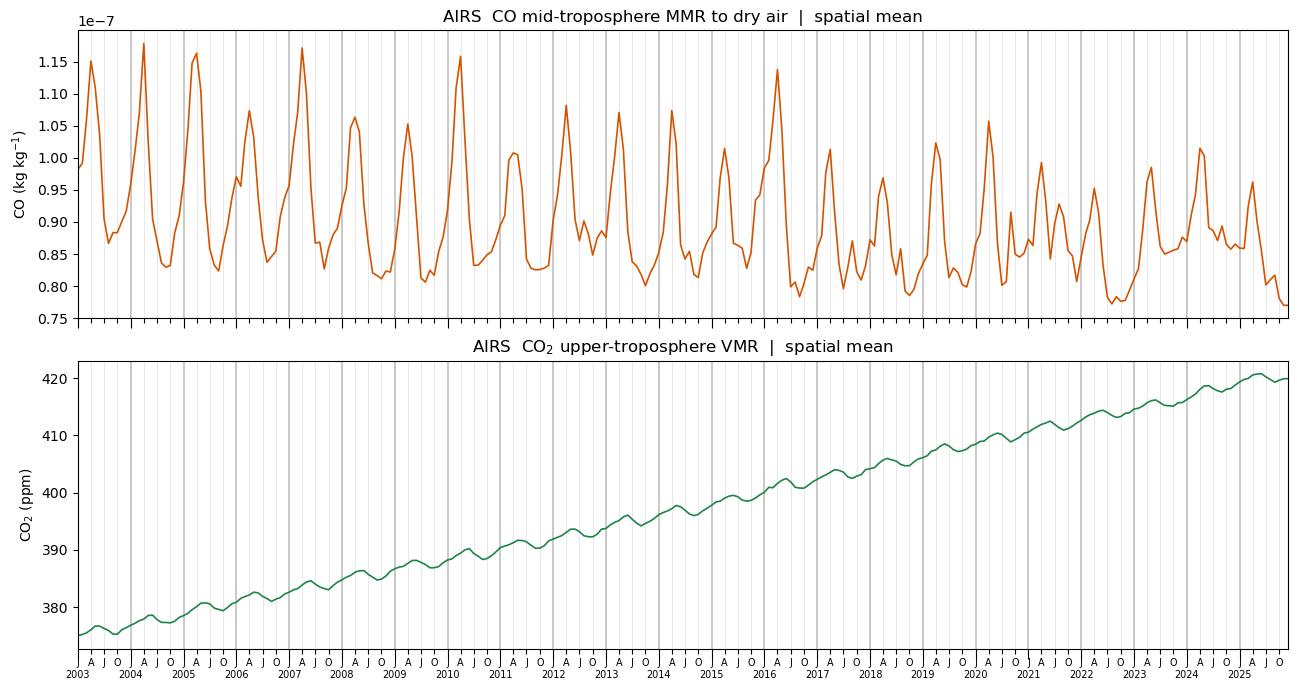

Saved -> ../Figures\timeseries_co_vs_co2_2003_2025.png


In [5]:
# CO built exactly as in detrend.ipynb (MMR x molar-mass ratio, gap-filled), no detrending.
co_maps, _, _ = load_cube(CO_VAR, MW_RATIO)
ts_co = co_maps.mean(dim=("lat", "lon"), skipna=True).values


def quarter_ticks(months):
    quarter_mask = months.month.isin([1, 4, 7, 10])
    tick_dates = months[quarter_mask]

    labels = []
    for d in tick_dates:
        letter = d.strftime("%b")[0]          # J, A, J, O
        if d.month == 1:
            labels.append(f"{letter}\n{d.year}")
        else:
            labels.append(letter)
    return tick_dates, labels


tick_dates, labels = quarter_ticks(ts_dates)

fig_cmp, (ax_co, ax_co2) = plt.subplots(2, 1, figsize=(13, 3.5 * 2), sharex=True)

ax_co.plot(ts_dates, ts_co, lw=1.2, color="#d35400")
ax_co.set_title("AIRS  CO mid-troposphere MMR to dry air  |  spatial mean")
ax_co.set_ylabel("CO (kg kg$^{-1}$)")

ax_co2.plot(ts_dates, ts_co2, lw=1.2, color="#1e8449")
ax_co2.set_title("AIRS  CO$_2$ upper-troposphere VMR  |  spatial mean")
ax_co2.set_ylabel("CO$_2$ (ppm)")

for ax in (ax_co, ax_co2):
    ax.set_xticks(tick_dates)
    ax.grid(axis="x", which="major", lw=0.4, alpha=0.5)

    # thicker tick marks and gridlines at January (year boundaries)
    for tick_date, tick in zip(tick_dates, ax.xaxis.get_major_ticks()):
        if tick_date.month == 1:
            tick.tick1line.set_markersize(7)
            tick.gridline.set_linewidth(1.2)
            tick.gridline.set_alpha(0.8)

ax_co2.set_xticklabels(labels, fontsize=7, rotation=0)
ax_co2.set_xlim(ts_dates[0], ts_dates[-1])

plt.tight_layout()
out_cmp = os.path.join(OUT_DIR, "timeseries_co_vs_co2_2003_2025.png")
fig_cmp.savefig(out_cmp, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_cmp)

## Detrended CO (top) vs detrended CO$_2$ (bottom)

CO  trend removed : -4.7343e-10 kg/kg per year
CO2 trend removed : 1.9964 ppm per year


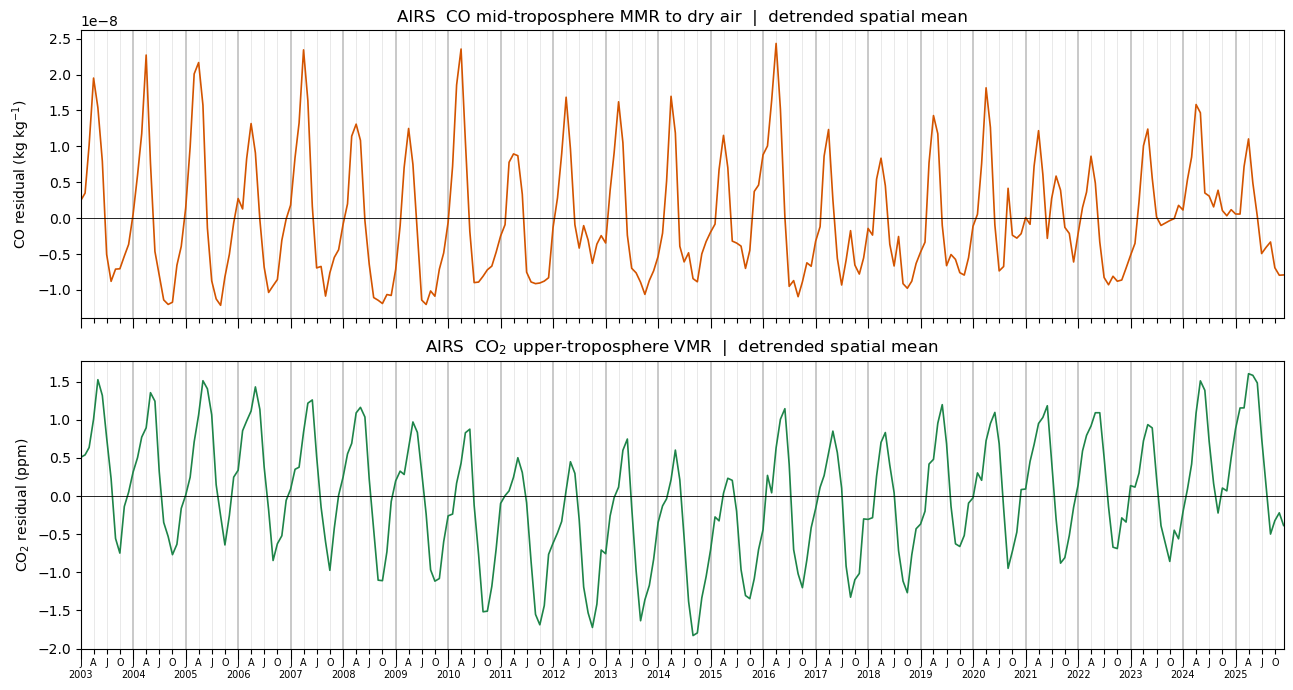

Saved -> ../Figures\timeseries_co_vs_co2_detrended_2003_2025.png


In [6]:
# OLS linear fit on each spatial-mean series, then subtract it.
# (Same result as detrend.ipynb's per-pixel fit followed by the spatial mean:
#  both steps are linear and the cubes have no NaNs.)
yr = np.arange(len(ts_dates)) / 12.0     # decimal years since Jan 2003


def detrend_series(y):
    slope, intercept = np.polyfit(yr, y, 1)
    return y - (intercept + slope * yr), slope


ts_co_dt,  co_slope  = detrend_series(ts_co)
ts_co2_dt, co2_slope = detrend_series(ts_co2)

print(f"CO  trend removed : {co_slope:.4e} kg/kg per year")
print(f"CO2 trend removed : {co2_slope:.4f} ppm per year")

fig_dt, (ax_co, ax_co2) = plt.subplots(2, 1, figsize=(13, 3.5 * 2), sharex=True)

ax_co.plot(ts_dates, ts_co_dt, lw=1.2, color="#d35400")
ax_co.axhline(0, color="k", lw=0.6)
ax_co.set_title("AIRS  CO mid-troposphere MMR to dry air  |  detrended spatial mean")
ax_co.set_ylabel("CO residual (kg kg$^{-1}$)")

ax_co2.plot(ts_dates, ts_co2_dt, lw=1.2, color="#1e8449")
ax_co2.axhline(0, color="k", lw=0.6)
ax_co2.set_title("AIRS  CO$_2$ upper-troposphere VMR  |  detrended spatial mean")
ax_co2.set_ylabel("CO$_2$ residual (ppm)")

for ax in (ax_co, ax_co2):
    ax.set_xticks(tick_dates)
    ax.grid(axis="x", which="major", lw=0.4, alpha=0.5)

    # thicker tick marks and gridlines at January (year boundaries)
    for tick_date, tick in zip(tick_dates, ax.xaxis.get_major_ticks()):
        if tick_date.month == 1:
            tick.tick1line.set_markersize(7)
            tick.gridline.set_linewidth(1.2)
            tick.gridline.set_alpha(0.8)

ax_co2.set_xticklabels(labels, fontsize=7, rotation=0)
ax_co2.set_xlim(ts_dates[0], ts_dates[-1])

plt.tight_layout()
out_dt = os.path.join(OUT_DIR, "timeseries_co_vs_co2_detrended_2003_2025.png")
fig_dt.savefig(out_dt, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_dt)

## Correlation between detrended CO and CO$_2$

Pearson r (lag 0) = 0.5904   p = 2.541e-27   N = 276
Strongest |r| at lag +1 months : r = 0.7452


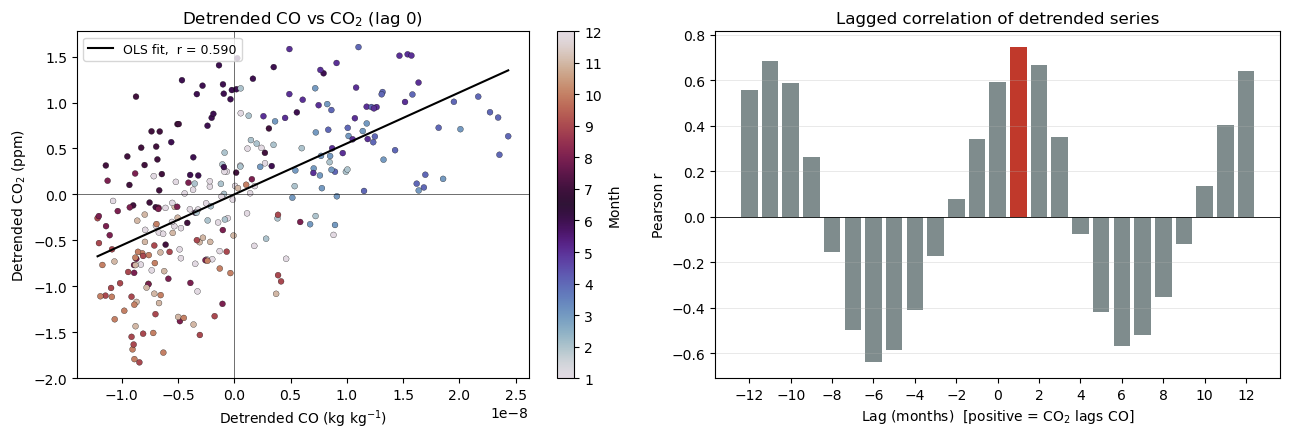

Saved -> ../Figures\correlation_co_co2_detrended_2003_2025.png


In [7]:
from scipy import stats

# Same-month (lag 0) Pearson correlation.
r, p = stats.pearsonr(ts_co_dt, ts_co2_dt)
print(f"Pearson r (lag 0) = {r:.4f}   p = {p:.3e}   N = {len(ts_co_dt)}")

# Lagged correlation: positive lag = CO2 lags CO by that many months.
lags = np.arange(-12, 13)
r_lag = np.array([
    np.corrcoef(ts_co_dt[max(0, -k):len(ts_co_dt) - max(0, k)],
                ts_co2_dt[max(0, k):len(ts_co2_dt) - max(0, -k)])[0, 1]
    for k in lags
])
k_best = lags[np.argmax(np.abs(r_lag))]
print(f"Strongest |r| at lag {k_best:+d} months : r = {r_lag[lags == k_best][0]:.4f}")

fig_c, (ax_sc, ax_lag) = plt.subplots(1, 2, figsize=(13, 4.5))

# Scatter of the detrended pairs, coloured by calendar month.
sc = ax_sc.scatter(ts_co_dt, ts_co2_dt, c=ts_dates.month, cmap="twilight",
                   s=18, edgecolor="k", linewidth=0.2)
m, c0 = np.polyfit(ts_co_dt, ts_co2_dt, 1)
xx = np.linspace(ts_co_dt.min(), ts_co_dt.max(), 50)
ax_sc.plot(xx, c0 + m * xx, color="k", lw=1.5, label=f"OLS fit,  r = {r:.3f}")
ax_sc.axhline(0, color="k", lw=0.4); ax_sc.axvline(0, color="k", lw=0.4)
ax_sc.set_xlabel("Detrended CO (kg kg$^{-1}$)")
ax_sc.set_ylabel("Detrended CO$_2$ (ppm)")
ax_sc.set_title("Detrended CO vs CO$_2$ (lag 0)")
ax_sc.legend(fontsize=9, loc="upper left")
cb = fig_c.colorbar(sc, ax=ax_sc, ticks=range(1, 13))
cb.set_label("Month")

# Lagged correlation.
ax_lag.bar(lags, r_lag, color=np.where(lags == k_best, "#c0392b", "#7f8c8d"))
ax_lag.axhline(0, color="k", lw=0.6)
ax_lag.set_xticks(lags[::2])
ax_lag.set_xlabel("Lag (months)  [positive = CO$_2$ lags CO]")
ax_lag.set_ylabel("Pearson r")
ax_lag.set_title("Lagged correlation of detrended series")
ax_lag.grid(axis="y", lw=0.4, alpha=0.5)

plt.tight_layout()
out_c = os.path.join(OUT_DIR, "correlation_co_co2_detrended_2003_2025.png")
fig_c.savefig(out_c, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_c)

## Scatter at lag +1 (CO$_2$ one month after CO)

Pearson r (lag +1) = 0.7452   p = 5.997e-50   N = 275


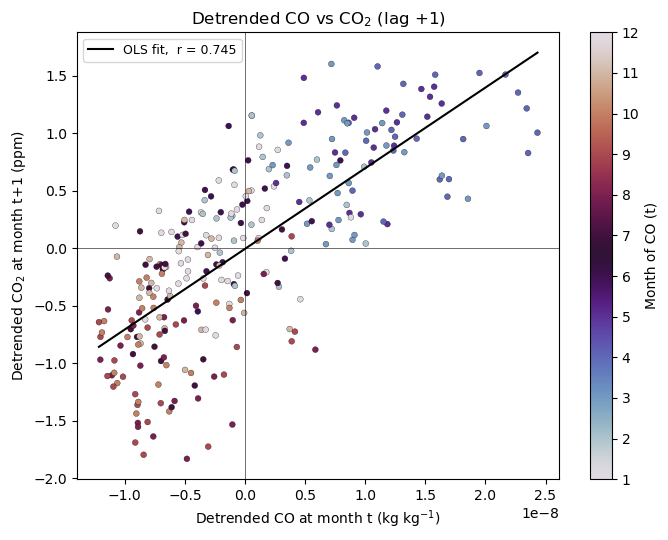

Saved -> ../Figures\scatter_co_co2_detrended_lag1_2003_2025.png


In [8]:
LAG = 1   # pair CO at month t with CO2 at month t + LAG

x_lag = ts_co_dt[:-LAG]
y_lag = ts_co2_dt[LAG:]
r1, p1 = stats.pearsonr(x_lag, y_lag)
print(f"Pearson r (lag +{LAG}) = {r1:.4f}   p = {p1:.3e}   N = {len(x_lag)}")

fig_l1, ax_l1 = plt.subplots(figsize=(7, 5.5))
sc = ax_l1.scatter(x_lag, y_lag, c=ts_dates.month[:-LAG], cmap="twilight",
                   s=18, edgecolor="k", linewidth=0.2)
m1, c1 = np.polyfit(x_lag, y_lag, 1)
xx = np.linspace(x_lag.min(), x_lag.max(), 50)
ax_l1.plot(xx, c1 + m1 * xx, color="k", lw=1.5, label=f"OLS fit,  r = {r1:.3f}")
ax_l1.axhline(0, color="k", lw=0.4); ax_l1.axvline(0, color="k", lw=0.4)
ax_l1.set_xlabel("Detrended CO at month t (kg kg$^{-1}$)")
ax_l1.set_ylabel(f"Detrended CO$_2$ at month t+{LAG} (ppm)")
ax_l1.set_title(f"Detrended CO vs CO$_2$ (lag +{LAG})")
ax_l1.legend(fontsize=9, loc="upper left")
cb = fig_l1.colorbar(sc, ax=ax_l1, ticks=range(1, 13))
cb.set_label("Month of CO (t)")

plt.tight_layout()
out_l1 = os.path.join(OUT_DIR, f"scatter_co_co2_detrended_lag{LAG}_2003_2025.png")
fig_l1.savefig(out_l1, dpi=150, bbox_inches="tight")
plt.show()
print("Saved ->", out_l1)